In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")


# Знакомство с данными

## 1. О датасете

**Wine Quality** (UCI Machine Learning Repository) — результаты физико-химического анализа португальского вина «Vinho Verde» и экспертная оценка его качества.

- 11 числовых признаков (кислотность, сахар, диоксид серы, плотность, pH, сульфаты, алкоголь и др.);
- целевая переменная `quality` — медиана оценок минимум 3 экспертов-дегустаторов, целое число (в этом датасете значения 3–8).

В датасете есть две части — красное и белое вино. Здесь используется **красное вино** (`winequality-red.csv`, 1599 объектов). Красное и белое вино заметно различаются по физико-химическому составу, поэтому их разумно моделировать отдельно; для красного вина разброс `quality` меньше, а эксперимент компактнее и воспроизводимее.

Важно: `quality` — **субъективная** экспертная оценка, усреднённая по нескольким людям. Значит, в ней есть шум, и часть разброса target принципиально не объясняется физико-химическими признаками. Это задаёт «потолок» качества любой модели.

In [ ]:
import os

DATA_DIR = "wine_quality"
red_path = os.path.join(DATA_DIR, "winequality-red.csv")

if not os.path.exists(red_path):
    os.makedirs(DATA_DIR, exist_ok=True)
    os.system('wget -O wine_quality.zip "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"')
    os.system("unzip -o wine_quality.zip -d " + DATA_DIR)

data = pd.read_csv(red_path, sep=";")
print("Размер датасета:", data.shape)
data.head()


Размер датасета: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Качество данных

Проверим пропуски, дубликаты, типы признаков и постоянные (константные) столбцы.

In [4]:
print("Типы признаков:")
print(data.dtypes.to_string())

print("\nПропуски:", int(data.isna().sum().sum()))
print("Полных дубликатов строк:", int(data.duplicated().sum()))

constant_columns = [c for c in data.columns if data[c].nunique() == 1]
print("Константные признаки:", constant_columns)

print("\nОписательные статистики:")
data.describe().T


Типы признаков:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64

Пропуски: 0
Полных дубликатов строк: 240
Константные признаки: []

Описательные статистики:


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


### Выводы по качеству данных

- **Пропусков нет** — дополнительная обработка пропущенных значений не требуется.
- **Все признаки числовые** (`float64`/`int64`), категориальных переменных нет, поэтому one-hot кодирование не нужно.
- **Константных признаков нет** — каждый признак принимает разные значения.
- **Есть 240 полных дубликатов строк** (≈15% от 1599). Это, скорее всего, повторные измерения или записи очень похожих вин.

In [ ]:
duplicates = data[data.duplicated(keep=False)].sort_values(list(data.columns))
print("Строк, участвующих в дубликатах:", len(duplicates))
print("Уникальных строк после удаления дубликатов:", data.drop_duplicates().shape[0])
duplicates.head(6)


Дубликаты удаляем до разбиения на выборки. Причины:

1. Если одинаковые строки попадут и в train, и в test, модель будет оцениваться на данных, которые фактически видела при обучении.
2. Идентичный физико-химический профиль не несёт новой информации, а лишь дублирует вес отдельных объектов.

После удаления дубликатов остаётся **1359** объектов.

In [5]:
data = data.drop_duplicates().reset_index(drop=True)
print("Рабочий датасет:", data.shape)


Рабочий датасет: (1359, 12)


## 3. Целевая переменная `quality`

Посмотрим на распределение оценки качества.

Описательные статистики quality:
count    1359.000
mean        5.623
std         0.824
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         8.000
Name: quality, dtype: float64

Частоты значений quality:
quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64


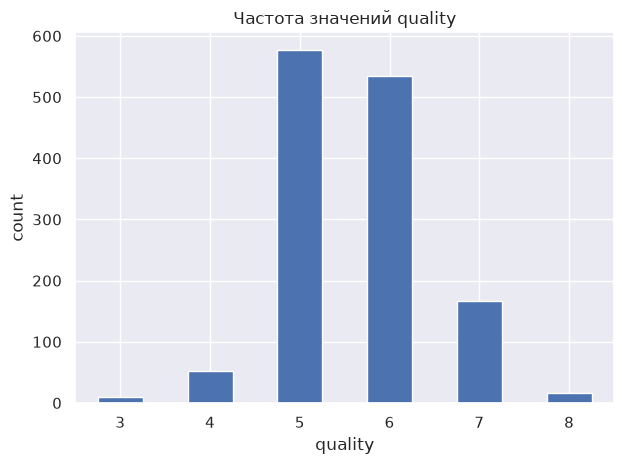

In [15]:
print("Описательные статистики quality:")
print(data["quality"].describe().round(3))
print("\nЧастоты значений quality:")
print(data["quality"].value_counts().sort_index())

data["quality"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.title("Частота значений quality")
plt.xlabel("quality")
plt.ylabel("count")
plt.tight_layout()


### Выводы по целевой переменной

- `quality` принимает **целые значения от 3 до 8**, то есть целевая переменная дискретная. Непрерывное предсказание здесь уместно, но дробные значения вида 5.7 не соответствуют реальным экспертным оценкам.
- Распределение **сильно несбалансировано**: «средние» оценки 5 и 6 — это ≈82% датасета, тогда как крайние оценки редки (`quality=3` — 10 объектов, `quality=8` — 17). Отсюда два следствия:
  - средние значения модель предсказывает хорошо, а **редкие — плохо** (для них мало примеров);
  - среднее `quality` ≈ 5.62 при стандартном отклонении ≈ 0.82 — это ориентир для baseline и масштаба ошибок: RMSE порядка 0.8 означает «ничего не предсказывать».
- Target **шумный** (субъективная экспертиза), поэтому идеально низкий RMSE ожидать нельзя.

## 4. Распределения признаков

Посмотрим на масштаб и форму распределений входных признаков.

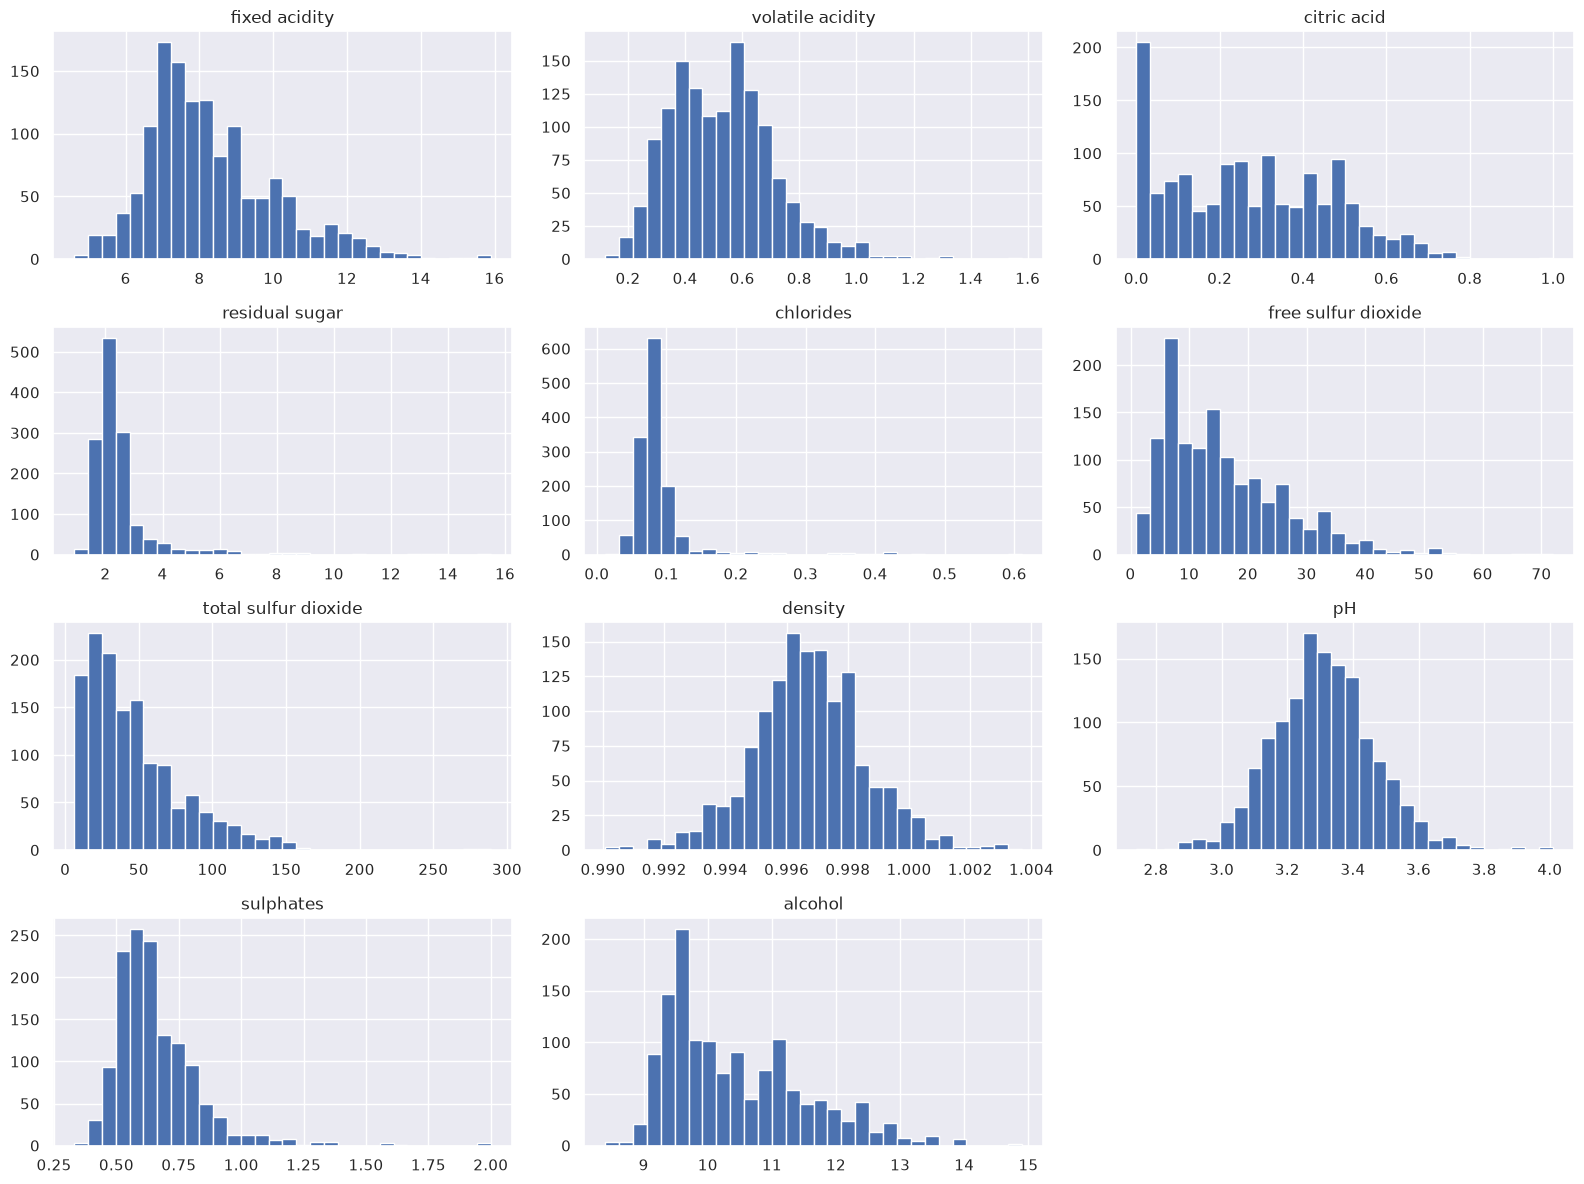

In [16]:
features = data.drop(columns=["quality"])
features.hist(figsize=(16, 12), bins=30)
plt.tight_layout()


### Выводы по распределениям признаков

- Признаки измеряются **в очень разных масштабах**: `total sulfur dioxide` — десятки (в среднем ≈46), `residual sugar` — единицы, `chlorides` — сотые (≈0.087), а `density` ≈ 1.0 с разбросом в третьем знаке.
- Многие распределения **скошены вправо** (асимметрия `residual sugar` ≈ 4.6, `chlorides` ≈ 5.5, `sulphates` ≈ 2.4): есть длинные «хвосты».
- Практический вывод: для **линейной регрессии** нужна стандартизация — иначе признаки с большим масштабом доминируют, а коэффициенты становятся несравнимыми между собой. Для **деревьев** (Random Forest, Gradient Boosting) масштабирование не требуется: они инвариантны к монотонным преобразованиям признаков. Скос и выбросы — повод внимательно смотреть на крупные ошибки модели.

## 5. Связь признаков с `quality`

Посчитаем корреляции признаков с целевой переменной.

volatile acidity       -0.395214
density                -0.184252
total sulfur dioxide   -0.177855
chlorides              -0.130988
pH                     -0.055245
free sulfur dioxide    -0.050463
residual sugar          0.013640
fixed acidity           0.119024
citric acid             0.228057
sulphates               0.248835
alcohol                 0.480343
dtype: float64

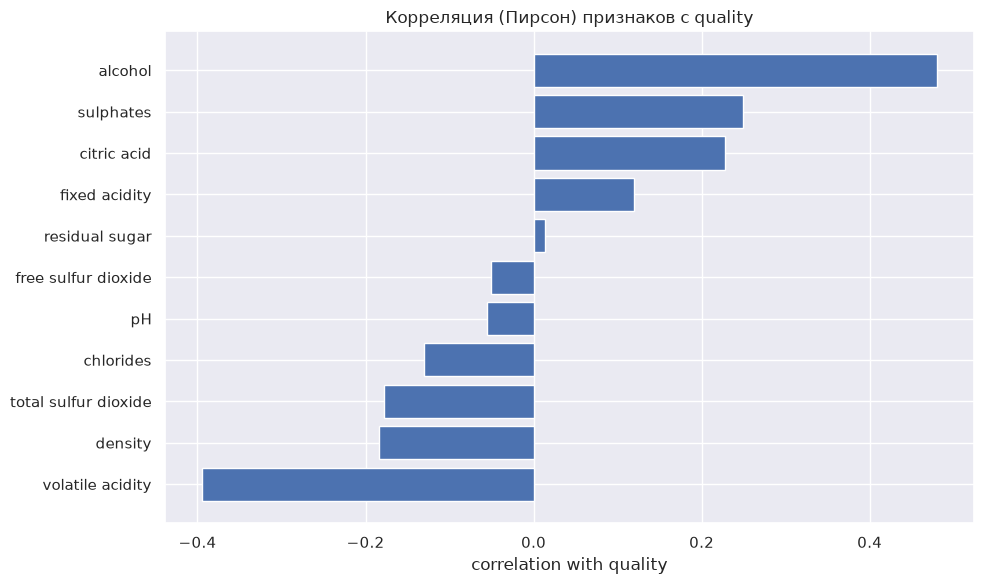

In [17]:
correlations = features.corrwith(data["quality"]).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(correlations.index, correlations.values)
plt.title("Корреляция (Пирсон) признаков с quality")
plt.xlabel("correlation with quality")
plt.tight_layout()

correlations


### Выводы по корреляциям

- **`alcohol` — сильнейшая положительная связь** (r ≈ 0.48): чем больше спирта, тем выше оценка. Ожидаемо — крепость связана с «телом» и восприятием вина.
- **`volatile acidity` — сильнейшая отрицательная связь** (r ≈ −0.40): летучая кислотность даёт уксусный привкус, её рост портит вино.
- Умеренный вклад у `sulphates` (+0.25) и `citric acid` (+0.23) — консервант и свежесть/кислотность.
- У `residual sugar`, `free sulfur dioxide` и `pH` корреляция близка к нулю (|r| < 0.06): линейной связи с качеством почти нет, «прямыми» линейными признаками они будут слабо полезны.

Дополнительно посмотрим на распределение `quality` в зависимости от двух самых сильных признаков.

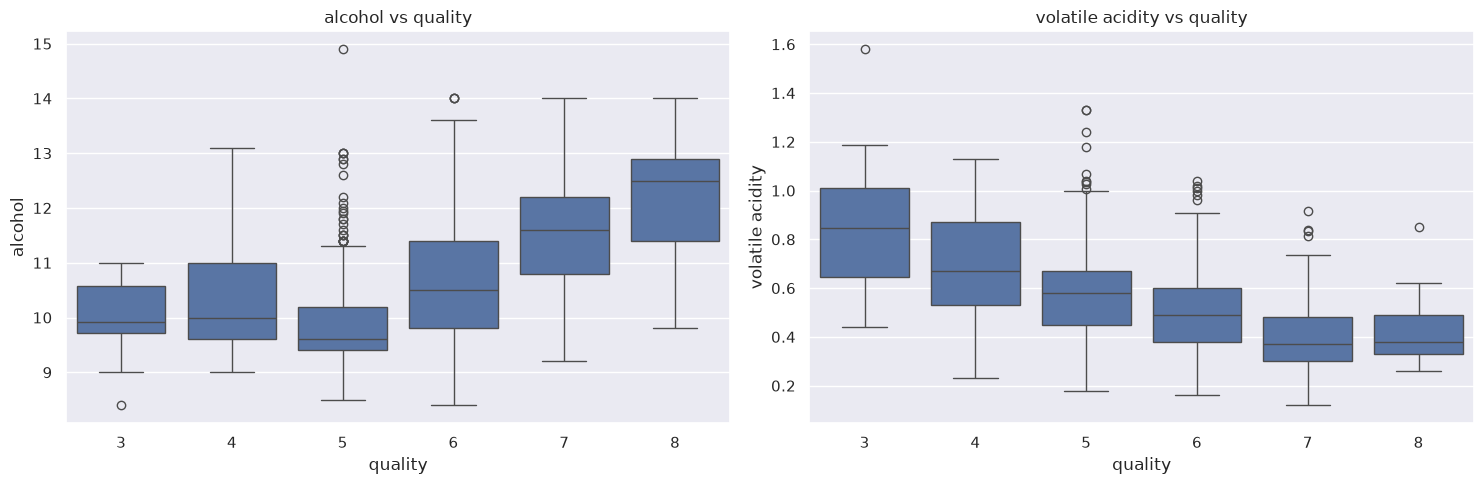

In [19]:
quality_cats = sorted(data["quality"].unique())
plot_data = data.assign(
    quality=pd.Categorical(data["quality"], categories=quality_cats, ordered=True)
)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=plot_data, x="quality", y="alcohol", ax=axs[0])
axs[0].set_title("alcohol vs quality")
sns.boxplot(data=plot_data, x="quality", y="volatile acidity", ax=axs[1])
axs[1].set_title("volatile acidity vs quality")
plt.tight_layout()


### Выводы по boxplot

- С ростом `quality` медиана `alcohol` **монотонно растёт**, а медиана `volatile acidity` **монотонно падает**. Зависимость монотонна (пусть и не строго линейна) — значит `alcohol` и `volatile acidity` действительно ключевые признаки.
- При этом «ящики» соседних оценок **сильно перекрываются**: только по `alcohol` нельзя уверенно отличить вино с оценкой 5 от 6. Это объясняет, почему даже хорошая модель не даст очень маленький RMSE — признаки сдвигают распределение, но не разделяют оценки.

## 6. Мультиколлинеарность

Линейная регрессия чувствительна к сильной корреляции между признаками, поэтому построим матрицу корреляций признаков.

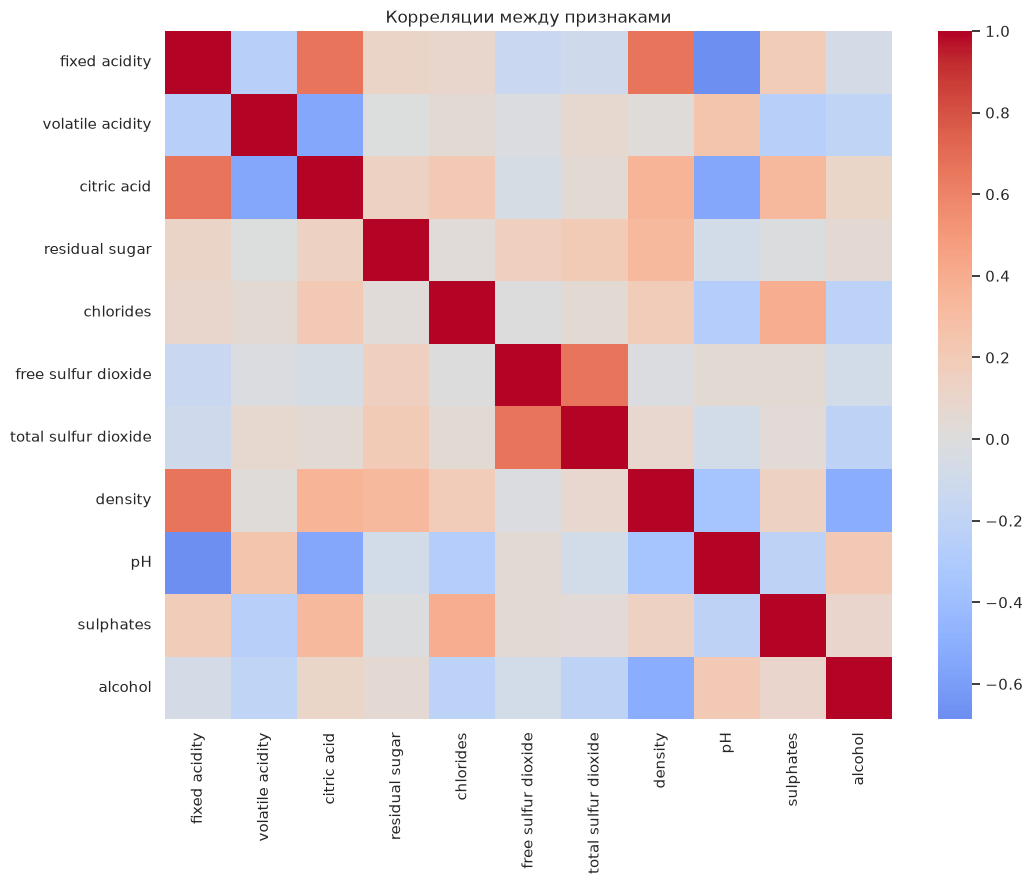

In [20]:
plt.figure(figsize=(11, 9))
sns.heatmap(data.drop(columns=["quality"]).corr(), cmap="coolwarm", center=0)
plt.title("Корреляции между признаками")
plt.tight_layout()


### Выводы по мультиколлинеарности

В данных есть заметные коррелированные группы:

- `fixed acidity` ↔ `pH` (r ≈ −0.69), `density` (≈ 0.67), `citric acid` (≈ 0.67);
- `free sulfur dioxide` ↔ `total sulfur dioxide` (≈ 0.67) — логично, так как total = free + связанный;
- `volatile acidity` ↔ `citric acid` (≈ 0.55), `citric acid` ↔ `pH` (≈ 0.55);
- `density` ↔ `alcohol` (≈ −0.51).

Что это значит для моделирования:

- для **линейной регрессии** сильная мультиколлинеарность делает коэффициенты **нестабильными** и трудно интерпретируемыми по знаку и величине;
- для **деревьев** это не мешает точности (алгоритм выбирает один из коррелированных признаков), но влияет на интерпретацию *feature importance*: важность «размазывается» между похожими признаками.

## 7. Выводы по разделу

1. Датасет — 1599 записей о красном вине, 11 числовых признаков; пропусков и констант нет. Убрали 240 дубликатов (осталось 1359) ради честной оценки.
2. `quality` — дискретный, несбалансированный и шумный (значения 3–8, оценки 5–6 доминируют). 
3. Ключевые признаки по корреляции и визуально: **`alcohol` (+) и `volatile acidity` (−)**, далее `sulphates` и `citric acid`.
4. Признаки разномасштабны и скошены — линейным моделям нужна стандартизация, деревьям она не нужна.
5. Есть мультиколлинеарные группы (`fixed acidity`/`pH`/`density`/`citric acid`; `free`/`total sulfur dioxide`), которые усложняют интерпретацию коэффициентов и важностей.

# Подготовка выборок

Разделим данные на обучающую и тестовую части.

Принципы:

- тестовая выборка используется **только один раз** — для финальной оценки; на неё нельзя «подглядывать» при выборе модели, признаков и гиперпараметров;
- `random_state` зафиксирован, чтобы разбиение было воспроизводимым.

In [ ]:
from sklearn.model_selection import train_test_split

X = data.drop(columns=["quality"])
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:  ", X_test.shape)


In [ ]:
split_summary = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
})
print("Доли значений quality в выборках, %:")
print((split_summary * 100).round(2).fillna(0))


## Почему выбрано именно такое разбиение

- **Размер.** Из 1359 объектов получаем **951 в train** и **408 в test** (70/30).
  - Train достаточно большой, чтобы модели видели разные комбинации признаков и редкие оценки.
  - Test (≈400 объектов) достаточно большой, чтобы RMSE оценивался **стабильно** и не «прыгал» от случайных объектов.
  - Для небольших датасетов 70/30 (или 80/20) — стандарт: отдавать под тест больше 30% расточительно (мало данных для обучения), меньше 20% — риск получить шумную оценку.
- **Способ разбиения.** Простое случайное разбиение (`train_test_split`). Оно подходит, потому что объекты **независимы** — нет временной или групповой структуры. Дубликаты мы уже удалили, поэтому одинаковые объекты не попадут одновременно в train и test.
- **`random_state=42`** фиксирует генератор случайных чисел: при повторном запуске разбиение будет точно таким же. Без этого нельзя воспроизвести результаты и честно сравнить модели «в одинаковых условиях».
- Доли значений `quality` в train и test близки (см. таблицу выше), поэтому стратифицированное разбиение не обязательно. Но для самой редкой оценки (`quality=8`) объектов всё равно мало (≈4 в тесте) — метрика по ней будет шумной.

## Проблема многократной оценки на одной тестовой выборке

Если много раз смотреть RMSE на тесте и по нему выбирать модель, признаки и гиперпараметры, тестовая выборка постепенно «протекает» в процесс принятия решений: мы невольно подбираем решение под конкретные 408 объектов. В результате:

- оценка становится **оптимистично смещённой** — на новых данных качество окажется хуже;
- теряется смысл теста как независимой проверки.

Поэтому по тесту смотрим **один раз**, в самом конце. Все промежуточные решения принимаем на обучающей выборке — например, через кросс-валидацию по train или отдельную валидационную часть внутри train.

# Baseline

## Какую константу выбрать

Константу подбираем под метрику:

- **RMSE** основан на $MSE(c) = \frac{1}{n}\sum_i (y_i - c)^2$. Этот функционал минимален при $c = \mathrm{mean}(y)$ → под основную метрику берём **среднее**.
- **MAE** $= \frac{1}{n}\sum_i |y_i - c|$ минимальна при $c = \mathrm{median}(y)$ → под MAE оптимальна **медиана**.

Основная метрика работы — RMSE, поэтому как baseline используем **среднее** `quality` по train. Медианный вариант считаем для сравнения.

In [24]:
import numpy as np
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

def scores(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred), mean_absolute_error(y_true, y_pred)

const_mean = y_train.mean()
const_median = y_train.median()

rmse_mean, mae_mean = scores(y_test, np.full(len(y_test), const_mean))
rmse_med, mae_med = scores(y_test, np.full(len(y_test), const_median))

print("Константа mean(y_train)   = %.4f" % const_mean)
print("Константа median(y_train) = %.4f" % const_median)
print()
print("Baseline (const = mean):   RMSE = %.4f  MAE = %.4f" % (rmse_mean, mae_mean))
print("Baseline (const = median): RMSE = %.4f  MAE = %.4f" % (rmse_med, mae_med))

Константа mean(y_train)   = 5.6246
Константа median(y_train) = 6.0000

Baseline (const = mean):   RMSE = 0.8227  MAE = 0.6900
Baseline (const = median): RMSE = 0.9061  MAE = 0.6642


## Вывод по baseline

Константа-медиана даёт меньшую MAE (0.664) и бо́льшую RMSE (0.906) — подтверждение, что у разных метрик разные оптимальные константы. Поэтому baseline зафиксирован как **mean**: он согласован с основной метрикой RMSE.

# Метрики

## Ответы на вопросы

- **Что показывает MAE:** среднюю величину ошибки в баллах `quality`, без усиления крупных промахов. Отвечает на вопрос «на сколько баллов в среднем мы ошибаемся».
- **Что показывает RMSE:** то же самое, но с акцентом на крупные ошибки, поскольку работает с квадратами. Отвечает на вопрос «насколько велики типичные и, особенно, большие промахи».
- **Почему RMSE сильнее реагирует на большие ошибки:** из-за возведения в квадрат — вклад ошибки растёт квадратично, поэтому один большой промах может заметно поднять RMSE.
- **Почему MAE и RMSE различаются:** они по-разному взвешивают ошибки — MAE линейно, RMSE квадратично. Чем более неоднородны ошибки (есть крупные промахи), тем больше расхождение.

## Для нашей задачи

- Метрика лидерборда — **RMSE**, по ней и сравниваем модели.
- MAE показываем дополнительно: она понятнее человеку.
- Обе метрики считаем на **одной и той же** тестовой выборке для всех моделей.

In [ ]:
examples = {
    "ровные ошибки":        np.array([1.0, 1.0, 1.0, 1.0]),
    "один крупный промах":  np.array([0.0, 0.0, 0.0, 4.0]),
}
for name, e in examples.items():
    print(f"{name:22s} MAE = {np.abs(e).mean():.2f}   RMSE = {np.sqrt((e ** 2).mean()):.2f}")

ровные ошибки          MAE = 1.00   RMSE = 1.00
один крупный промах    MAE = 1.00   RMSE = 2.00


# Обучение модели

## Линейная регрессия

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

pipeline = Pipeline([
    ("regressor", LinearRegression()),
])
model = pipeline.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Linear Regression")
print("Test RMSE = %.4f" % root_mean_squared_error(y_test, y_pred))
print("Test MAE  = %.4f" % mean_absolute_error(y_test, y_pred))

Linear Regression
Test RMSE = 0.6470
Test MAE  = 0.4944


In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

scaled_linear = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
]).fit(X_train, y_train)

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", Ridge()),
]).fit(X_train, y_train)

for name, model in [("Linear (scaled)", scaled_linear), ("Ridge", ridge)]:
    train_rmse = root_mean_squared_error(y_train, model.predict(X_train))
    train_mae = mean_absolute_error(y_train, model.predict(X_train))
    print(f"{name:12s} train RMSE={train_rmse:.4f} MAE={train_mae:.4f}")

coefficients = pd.DataFrame({
    "Linear": scaled_linear.named_steps["regressor"].coef_,
    "Ridge": ridge.named_steps["regressor"].coef_,
}, index=X_train.columns)
coefficients = coefficients.reindex(coefficients["Ridge"].abs().sort_values(ascending=False).index)
coefficients.round(3)

Linear (scaled) train RMSE=0.6639 MAE=0.5171
Ridge        train RMSE=0.6639 MAE=0.5170


,Linear,Ridge
alcohol,0.328,0.326
volatile acidity,-0.176,-0.176
sulphates,0.152,0.152
total sulfur dioxide,-0.125,-0.124
pH,-0.123,-0.122
chlorides,-0.097,-0.097
free sulfur dioxide,0.068,0.068
fixed acidity,-0.054,-0.052
density,0.038,0.036
residual sugar,-0.024,-0.023


In [41]:
for name, model in [("Linear (scaled)", scaled_linear), ("Ridge", ridge)]:
    test_rmse = root_mean_squared_error(y_test, model.predict(X_test))
    test_mae = mean_absolute_error(y_test, model.predict(X_test))
    print(f"test RMSE={test_rmse:.4f} MAE={test_mae:.4f}")

test RMSE=0.6470 MAE=0.4944
test RMSE=0.6468 MAE=0.4943


### Интерпретация коэффициентов

Таблица выше — при **стандартизованных** признаках (`StandardScaler`). Поэтому каждая величина читается одинаково для всех признаков: **на сколько баллов `quality` изменится при росте признака на одно стандартное отклонение, при прочих равных**. 

**Самые влиятельные признаки:**

- `alcohol` — **+0.33**: главный положительный вклад. Рост на 1 σ алкоголя (≈1.08 %vol) повышает предсказанное `quality` примерно на **+0.33 балла**. Крепость — сильнейший сигнал качества.
- `volatile acidity` — **−0.18**: главный отрицательный вклад. Рост на 1 σ летучей кислотности (≈0.18 г/л) снижает оценку на **−0.18 балла**. Уксусный привкус портит вино.
- `sulphates` — **+0.15**, `total sulfur dioxide` — **−0.12**, `pH` — **−0.12**, `chlorides` — **−0.10**: заметный, но умеренный вклад.

**Слабые признаки (коэффициент ≈ 0):** `citric acid` (≈0.004), `residual sugar` (−0.024), `density` (+0.038), `fixed acidity` (−0.054). В рамках линейной модели они почти не меняют предсказание.

**Сопоставление с анализом — и важный контраст.** Часть коэффициентов расходится с корреляциями из раздела 5:

- `density`: корреляция с `quality` ≈ **−0.18**, а коэффициент в модели **+0.04** — знак сменился;
- `fixed acidity`: корреляция ≈ **+0.12**, а коэффициент **−0.05** — знак сменился;
- `citric acid`: корреляция ≈ **+0.23**, а коэффициент почти **0**.

Причина — **мультиколлинеарность**. Модель передала общий вклад одному признаку из сильно коррелированных между собой - признаку `pH`. 

**Влияние регуляризации** При `alpha = 1.0` коэффициенты Ridge практически совпадают с обычной регрессией (расхождения ≤ 0.003) — регуляризация слабая. Это ожидаемо: `p = 11 ≪ n = 951`, переобучения нет, стягивать веса почти нечего.

## Случайный лес (Random Forest)


In [82]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

random_forest = RandomForestRegressor(
    n_estimators=500,
    random_state=42,
    oob_score=True,
    n_jobs=-1,
    min_samples_leaf=8,
)
random_forest.fit(X_train, y_train)

print("Random Forest")
print("train RMSE = %.4f  MAE = %.4f" % (
    root_mean_squared_error(y_train, random_forest.predict(X_train)),
    mean_absolute_error(y_train, random_forest.predict(X_train)),
))
print("OOB R^2 = %.4f" % random_forest.oob_score_)

Random Forest
train RMSE = 0.5038  MAE = 0.3838
OOB R^2 = 0.3478


In [83]:
print("test  RMSE = %.4f  MAE = %.4f" % (
    root_mean_squared_error(y_test, random_forest.predict(X_test)),
    mean_absolute_error(y_test, random_forest.predict(X_test)),
))

test  RMSE = 0.6076  MAE = 0.4674


### Feature importance

`feature_importances_` у леса основана на **среднем снижении примеси** (*impurity*): насколько каждый признак уменьшает разброс target в узлах, где он используется, в среднем по всем деревьям. Значения нормированы и в сумме дают 1.

alcohol                 0.3743
sulphates               0.1649
volatile acidity        0.1338
total sulfur dioxide    0.0668
chlorides               0.0475
pH                      0.0449
free sulfur dioxide     0.0346
citric acid             0.0345
density                 0.0340
fixed acidity           0.0337
residual sugar          0.0309
dtype: float64

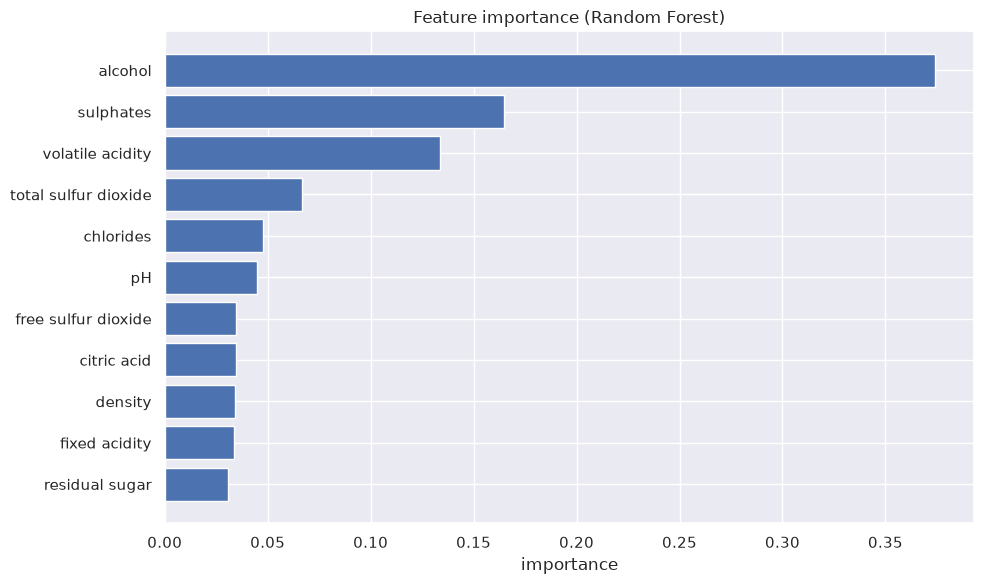

In [84]:
importances = pd.Series(
    random_forest.feature_importances_, index=X_train.columns
).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importances.index, importances.values)
plt.title("Feature importance (Random Forest)")
plt.xlabel("importance")
plt.tight_layout()

importances[::-1].round(4)

In [85]:
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    random_forest, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1,
    scoring="neg_root_mean_squared_error",
)
permutation_importance = pd.Series(
    permutation.importances_mean, index=X_test.columns
).sort_values(ascending=False)
permutation_importance.round(4)

alcohol                 0.1561
sulphates               0.0796
volatile acidity        0.0423
total sulfur dioxide    0.0143
pH                      0.0084
free sulfur dioxide     0.0079
density                 0.0041
fixed acidity           0.0028
chlorides               0.0027
citric acid             0.0009
residual sugar          0.0002
dtype: float64

### Интерпретация feature importance

Топ признаков (impurity-based):

- `alcohol` — **0.374**, с большим отрывом главный признак;
- `sulphates` — **0.165**, `volatile acidity` — **0.134**;
- далее `total sulfur dioxide` (0.067), `chlorides` (0.048), `pH` (0.045), а затем длинный «хвост» слабых признаков — `free sulfur dioxide` (0.035), `citric acid` (0.034), `density` (0.034), `fixed acidity` (0.034), `residual sugar` (0.031).

Сопоставление с линейной моделью и исследованием датасета:

- **`alcohol`** — лидер и в линейных коэффициентах, и в корреляциях, и здесь. Вывод устойчив.
- **`sulphates`** и **`volatile acidity`** — на 2–3 месте во всех трёх подходах.
- Различие: в линейной модели `residual sugar`, `citric acid`, `density`, `fixed acidity` имели коэффициент ≈ 0, а лес даёт им важности 0.03–0.035. Это ожидаемо: лес ловит **нелинейности и взаимодействия**, которые линейная модель игнорирует, а impurity-важность «размывается» по всем признакам.

Permutation importance (падение качества при перемешивании признака на тесте) концентрируется сильнее: `alcohol` ≈ 0.156, `sulphates` ≈ 0.080, `volatile acidity` ≈ 0.042, у слабых признаков — значения около нуля (у `residual sugar` и `citric acid` порядка 0.0002–0.001, т.е. чистый шум). Обе меры согласны в топ-3.

## Градиентный бустинг (Gradient Boosting)

Бустинг строит деревья **последовательно**: каждое следующее дерево обучается не на исходном target, а на **остатках** (ошибках) всех предыдущих деревьев. Предсказание — сумма вкладов всех деревьев, взвешенная на `learning_rate`.

In [104]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

gradient_boosting = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=3,
    random_state=42,
)
gradient_boosting.fit(X_train, y_train)

print("Gradient Boosting")
print("train RMSE = %.4f  MAE = %.4f" % (
    root_mean_squared_error(y_train, gradient_boosting.predict(X_train)),
    mean_absolute_error(y_train, gradient_boosting.predict(X_train)),
))

Gradient Boosting
train RMSE = 0.5238  MAE = 0.4171


In [105]:
print("test  RMSE = %.4f  MAE = %.4f" % (
    root_mean_squared_error(y_test, gradient_boosting.predict(X_test)),
    mean_absolute_error(y_test, gradient_boosting.predict(X_test)),
))

test  RMSE = 0.6142  MAE = 0.4777


### Feature importance

Как и у леса, бустинг возвращает `feature_importances_` на основе **среднего снижения примеси**.

alcohol                 0.3902
sulphates               0.1657
volatile acidity        0.1401
total sulfur dioxide    0.0743
pH                      0.0584
chlorides               0.0422
fixed acidity           0.0351
density                 0.0315
residual sugar          0.0239
free sulfur dioxide     0.0203
citric acid             0.0183
dtype: float64

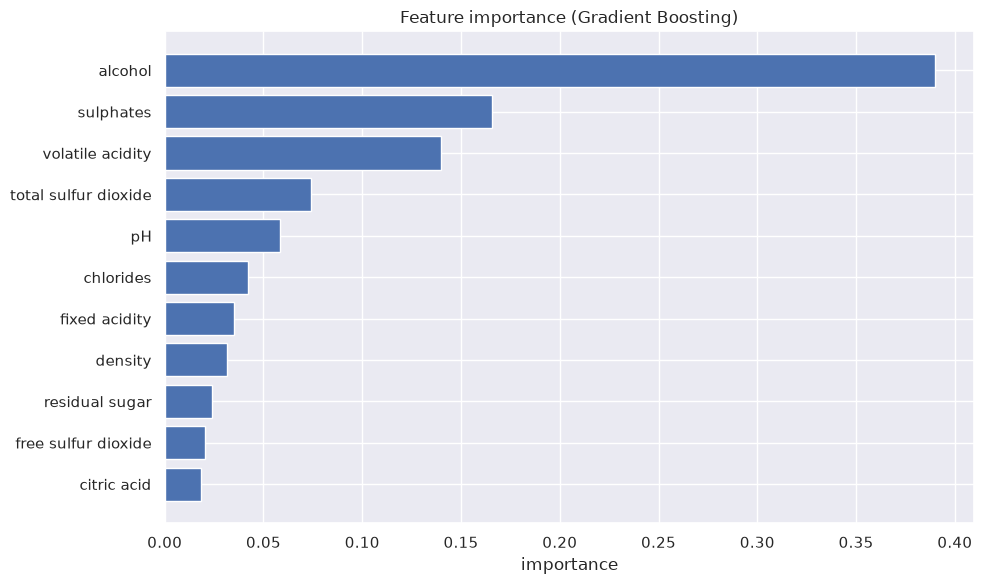

In [106]:
gb_importances = pd.Series(
    gradient_boosting.feature_importances_, index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(gb_importances.index[::-1], gb_importances.values[::-1])
plt.title("Feature importance (Gradient Boosting)")
plt.xlabel("importance")
plt.tight_layout()

gb_importances.round(4)

In [107]:
comparison = pd.DataFrame({
    "Gradient Boosting": gb_importances,
    "Random Forest": pd.Series(random_forest.feature_importances_, index=X_train.columns),
}).sort_values("Gradient Boosting", ascending=False)
comparison.round(4)

,Gradient Boosting,Random Forest
alcohol,0.3902,0.3743
sulphates,0.1657,0.1649
volatile acidity,0.1401,0.1338
total sulfur dioxide,0.0743,0.0668
pH,0.0584,0.0449
chlorides,0.0422,0.0475
fixed acidity,0.0351,0.0337
density,0.0315,0.0340
residual sugar,0.0239,0.0309
free sulfur dioxide,0.0203,0.0346


### Интерпретация и сравнение с лесом

Топ признаков (Gradient Boosting):

- `alcohol` — **0.390**, с большим отрывом;
- `sulphates` — **0.166**, `volatile acidity` — **0.140**;
- далее `total sulfur dioxide` (0.074), `pH` (0.058), `chlorides` (0.042), затем длинный хвост (0.018–0.035).

Сравнение с Random Forest: **топ-3 совпадает и в том же порядке** — `alcohol`, `sulphates`, `volatile acidity`. Это ещё одно подтверждение устойчивости вывода.

Различия в хвосте:

- `pH` бустинг ставит выше (0.058 против 0.045 у леса);
- `citric acid` и `free sulfur dioxide` — ниже (0.018 и 0.020 против 0.035 у леса).

Причина: важность у бустинга считается по деревьям, обученным на **остатках**, и зависит от `n_estimators` и `learning_rate` — вклад «добирается» до финального приближения иначе, чем у леса. Оба метода по-прежнему «размазывают» важность по коррелированным признакам, поэтому хвост ненадёжен.

Метрики: бустинг на тесте **RMSE 0.6142 / MAE 0.4777** — чуть хуже леса (0.6076 / 0.4674), но оба заметно лучше линейной регрессии (0.6470) и baseline (0.8227). Это согласуется с тем, что ключевую роль играют нелинейности и взаимодействия признаков.